# QuickBasket Churn Analysis: Complete Solution

**Goal:** find out *why* customers churn, build a model that flags likely churners, and turn it into a cost-justified retention plan.

**What was wrong with the first attempt (and what this notebook fixes):**

| Issue in the first attempt | Fix here |
|---|---|
| Judged by accuracy (78.75%), which a "nobody churns" model nearly matches | PR-AUC, recall, precision and **₹ net benefit** |
| Default 0.5 threshold, recall only 0.23 | **Cost-based threshold** chosen on out-of-fold predictions |
| Preprocessing/leakage details unclear | `Pipeline` + `ColumnTransformer`, fitted on train only |
| One model, one split | 3 models, 5-fold stratified CV |
| Model score only, no explanation | Coefficients, permutation importance, SHAP, segment analysis |
| No business answer | "Who is right?" evidence table, risk tiers, recommendations |

**Business assumptions (from the client brief):** lifetime value of a churner = ₹3,000; retention coupon = ₹150; the coupon is assumed to save **30%** of the churners who receive it (a parameter you should replace with a measured number from an A/B test).

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
LTV, COUPON, SAVE_RATE = 3000, 150, 0.30   # business assumptions (₹, ₹, fraction of churners saved by an offer)
TARGET = "churned_next_60d"

## 2. Load data and data-quality audit

In [2]:
raw = pd.read_csv("quickbasket_customer_data.csv")
print("Shape:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate customer_ids:", raw.customer_id.duplicated().sum())
print("\nMissing values (count):")
print(raw.isna().sum()[lambda s: s > 0])
print("\nOrder-value outliers (> ₹10,000):", (raw.avg_order_value_inr > 10000).sum())
raw.describe().T[["min", "50%", "mean", "max"]].round(1)

Shape: (6030, 27)
Duplicate rows: 30
Duplicate customer_ids: 30

Missing values (count):
age                            60
gender                         25
avg_order_value_inr            40
avg_ticket_resolution_hrs    3031
last_csat_score              2159
app_store_rating_given       4851
dtype: int64

Order-value outliers (> ₹10,000): 8


,min,50%,mean,max
age,18.0,32.0,32.1,69.0
first_order_discount_pct,0.0,10.0,15.6,50.0
tenure_days,30.0,374.0,374.0,719.0
orders_last_90d,0.0,5.0,5.3,24.0
avg_order_value_inr,120.0,427.0,547.6,99999.0
avg_delivery_fee_inr,0.0,29.0,26.8,59.0
avg_delivery_time_min,12.0,32.7,33.6,61.8
late_delivery_pct,0.0,13.0,15.2,66.4
order_cancellation_pct,0.0,3.2,3.8,23.2
missing_or_wrong_items_pct,0.0,2.5,3.2,21.1


## 3. Cleaning and feature engineering

* Drop exact duplicates.
* Treat absurd order values (> ₹10,000) as data-entry errors → set to missing and impute later.
* `avg_ticket_resolution_hrs` is blank **because there were no tickets**, so the correct fill is 0, not the median.
* `last_csat_score` and `app_store_rating_given` are blank because the customer didn't respond. Not responding can itself be a signal, so we keep a **missing flag**.
* `fee_to_basket_ratio` captures "small basket, high fee" pain, which is more informative than either number alone.
* `customer_id` and `signup_date` are dropped from the features (an ID has no signal; `tenure_days` already encodes signup date).

In [3]:
df = raw.drop_duplicates().reset_index(drop=True).copy()
df.loc[df.avg_order_value_inr > 10000, "avg_order_value_inr"] = np.nan

df["csat_missing"]        = df.last_csat_score.isna().astype(int)
df["app_rating_missing"]  = df.app_store_rating_given.isna().astype(int)
df["avg_ticket_resolution_hrs"] = df.avg_ticket_resolution_hrs.fillna(0)
df["fee_to_basket_ratio"] = df.avg_delivery_fee_inr / df.avg_order_value_inr

print("Clean shape:", df.shape)
print(f"Churn rate: {df[TARGET].mean():.1%}  ({df[TARGET].sum()} of {len(df)} customers)")

Clean shape: (6000, 30)
Churn rate: 22.7%  (1363 of 6000 customers)


## 4. Exploratory analysis: where is churn concentrated?

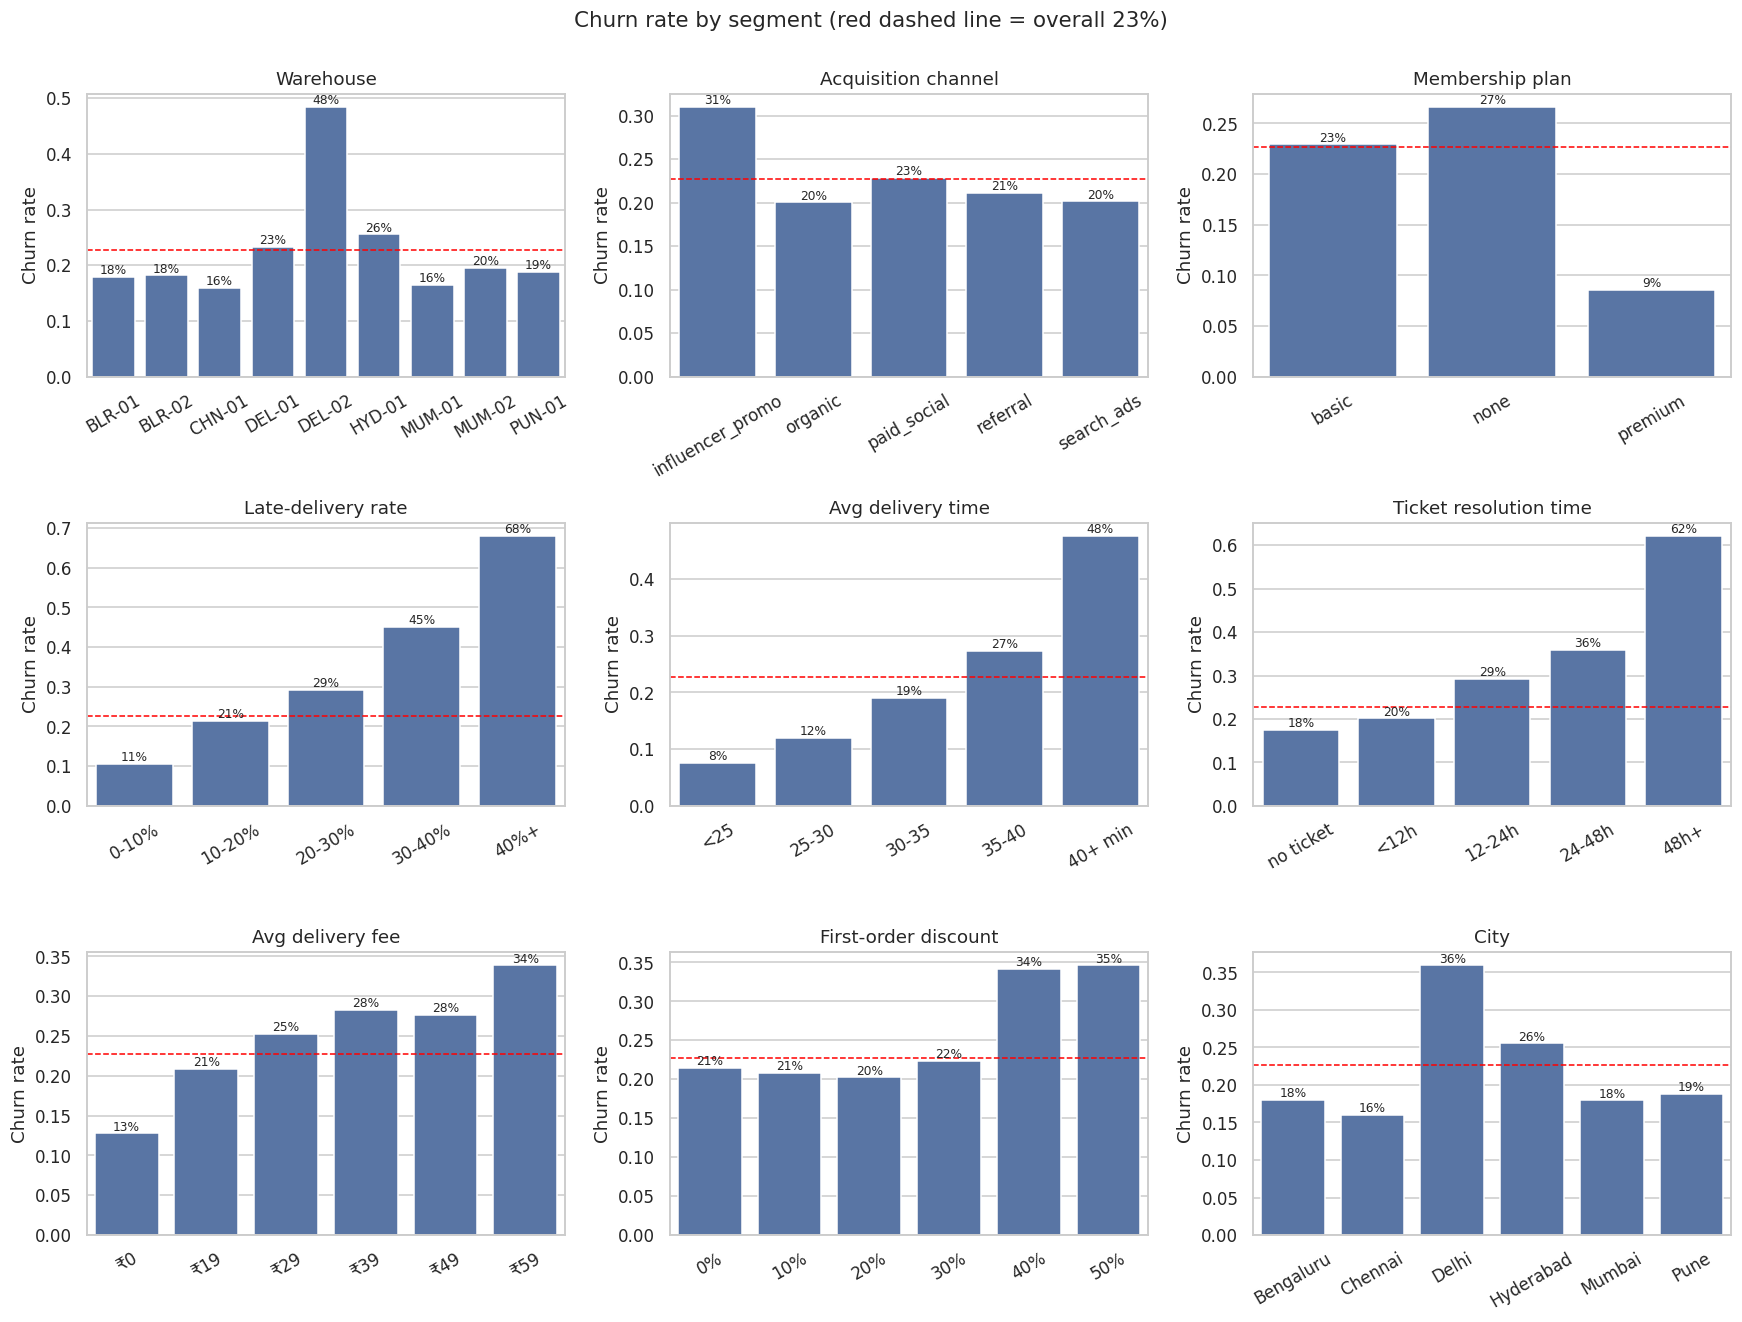

In [4]:
def bucket(s, bins, labels): return pd.cut(s, bins=bins, labels=labels)

df["late_bucket"]     = bucket(df.late_delivery_pct, [-1,10,20,30,40,100], ["0-10%","10-20%","20-30%","30-40%","40%+"])
df["delivery_bucket"] = bucket(df.avg_delivery_time_min, [0,25,30,35,40,200], ["<25","25-30","30-35","35-40","40+ min"])
df["resolution_bucket"] = bucket(df.avg_ticket_resolution_hrs, [-1,0,12,24,48,500], ["no ticket","<12h","12-24h","24-48h","48h+"])
df["fee_bucket"]      = df.avg_delivery_fee_inr.astype(int).astype(str).radd("₹")
df["discount_bucket"] = df.first_order_discount_pct.astype(int).astype(str).add("%")

panels = [("warehouse_id", "Warehouse"), ("acquisition_channel", "Acquisition channel"),
          ("membership_plan", "Membership plan"), ("late_bucket", "Late-delivery rate"),
          ("delivery_bucket", "Avg delivery time"), ("resolution_bucket", "Ticket resolution time"),
          ("fee_bucket", "Avg delivery fee"), ("discount_bucket", "First-order discount"),
          ("city", "City")]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
base = df[TARGET].mean()
for ax, (col, title) in zip(axes.ravel(), panels):
    g = df.groupby(col, observed=True)[TARGET].mean().reset_index()
    sns.barplot(data=g, x=col, y=TARGET, ax=ax, color="#4C72B0")
    ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=30)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0%}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.suptitle(f"Churn rate by segment (red dashed line = overall {base:.0%})", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

In [5]:
wh = (df.groupby("warehouse_id")
        .agg(customers=(TARGET, "size"), churn_rate=(TARGET, "mean"),
             avg_delivery_min=("avg_delivery_time_min", "mean"),
             late_pct=("late_delivery_pct", "mean"),
             wrong_items_pct=("missing_or_wrong_items_pct", "mean"),
             resolution_hrs=("avg_ticket_resolution_hrs", lambda s: s[s > 0].mean()))
        .round(2).sort_values("churn_rate", ascending=False))
wh

,customers,churn_rate,avg_delivery_min,late_pct,wrong_items_pct,resolution_hrs
warehouse_id,,,,,,
DEL-02,665,0.48,45.38,35.85,2.65,25.05
HYD-01,697,0.26,37.59,21.77,2.89,15.39
DEL-01,660,0.23,31.31,11.68,2.91,25.08
MUM-02,641,0.20,31.02,10.87,6.95,15.10
PUN-01,579,0.19,31.39,11.15,2.69,14.82
BLR-01,730,0.18,31.10,11.02,2.74,15.59
BLR-02,743,0.18,31.68,11.91,2.79,14.87
CHN-01,594,0.16,31.09,10.38,2.81,15.55
MUM-01,691,0.16,31.39,11.40,2.91,15.00


## 5. Who is right? Testing each team's claim with evidence

For each hypothesis we define the "problem segment", then compare its churn rate with everyone else and measure how many of all churners it contains. **Relative risk** = churn rate inside ÷ churn rate outside.

In [6]:
hyp = {
 "Ops: warehouse DEL-02":                   df.warehouse_id == "DEL-02",
 "Ops: late deliveries >= 40% of orders":   df.late_delivery_pct >= 40,
 "Ops: avg delivery time >= 40 min":        df.avg_delivery_time_min >= 40,
 "Support: ticket resolution >= 24h":       df.avg_ticket_resolution_hrs >= 24,
 "Finance: delivery fee >= ₹39":            df.avg_delivery_fee_inr >= 39,
 "Marketing: first-order discount >= 40%":  df.first_order_discount_pct >= 40,
 "Marketing: influencer_promo channel":     df.acquisition_channel == "influencer_promo",
 "Product: wrong/missing items >= 8%":      df.missing_or_wrong_items_pct >= 8,
 "Retention: no membership":                df.membership_plan == "none",
}
rows = []
total_churners = df[TARGET].sum()
for name, m in hyp.items():
    inside, outside = df.loc[m, TARGET], df.loc[~m, TARGET]
    rows.append({"hypothesis": name, "segment_size": int(m.sum()), "% of customers": m.mean(),
                 "churn_inside": inside.mean(), "churn_outside": outside.mean(),
                 "relative_risk": inside.mean()/outside.mean(), "% of all churners": inside.sum()/total_churners})
evidence = pd.DataFrame(rows).sort_values("relative_risk", ascending=False).reset_index(drop=True)
(evidence.style.format({"% of customers": "{:.0%}", "churn_inside": "{:.0%}", "churn_outside": "{:.0%}",
                        "relative_risk": "{:.2f}x", "% of all churners": "{:.0%}"})
         .background_gradient(subset=["relative_risk"], cmap="Reds"))

,hypothesis,segment_size,% of customers,churn_inside,churn_outside,relative_risk,% of all churners
0,Ops: late deliveries >= 40% of orders,291,5%,68%,20%,3.31x,14%
1,Ops: avg delivery time >= 40 min,1024,17%,47%,18%,2.68x,36%
2,Ops: warehouse DEL-02,665,11%,48%,20%,2.48x,24%
3,Support: ticket resolution >= 24h,689,11%,37%,21%,1.79x,19%
4,Finance: delivery fee >= ₹39,2445,41%,30%,18%,1.69x,54%
5,Marketing: first-order discount >= 40%,766,13%,34%,21%,1.63x,19%
6,Retention: no membership,3498,58%,27%,17%,1.54x,68%
7,Marketing: influencer_promo channel,1078,18%,31%,21%,1.48x,25%
8,Product: wrong/missing items >= 8%,418,7%,25%,23%,1.09x,8%


> **How to read this:** a high relative risk on a *small* segment is a precision fix (e.g. one warehouse); a moderate relative risk on a *large* segment, or a big "% of all churners", is where the volume is. Correlated causes overlap, which is why the model in the next sections is needed to separate them.

## 6. Leakage check and feature set

**Timing rule:** every feature must be known **on or before 30 Sep 2026**, and the target describes the 60 days **after**. All features here satisfy that, so there is no *temporal* leakage. The things to be careful about are:

* `customer_id`: no signal, can cause memorisation → dropped.
* `signup_date`: redundant with `tenure_days` → dropped.
* `days_since_last_order` and `orders_last_90d`: legitimate (known at scoring time) but **behavioural symptoms of disengagement**, not root causes. They make the model accurate but don't tell the business *why*. Below we measure how much of the model's power depends on them.

In [7]:
cat_cols = ["city", "warehouse_id", "gender", "acquisition_channel", "membership_plan", "preferred_payment", "top_category"]
engineered_helpers = ["late_bucket", "delivery_bucket", "resolution_bucket", "fee_bucket", "discount_bucket", "app_store_rating_given"]
all_features = [c for c in df.columns if c not in ["customer_id", "signup_date", TARGET] + engineered_helpers]
num_cols = [c for c in all_features if c not in cat_cols]
print(f"{len(all_features)} features: {len(num_cols)} numeric, {len(cat_cols)} categorical")

def make_preprocessor(num, cat, scale=True):
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_scores(features, model=None):
    num = [c for c in features if c in num_cols]; cat = [c for c in features if c in cat_cols]
    model = model or LogisticRegression(max_iter=3000)
    pipe = Pipeline([("pre", make_preprocessor(num, cat)), ("clf", model)])
    r = cross_validate(pipe, df[features], df[TARGET], cv=cv, scoring=["roc_auc", "average_precision"])
    return r["test_roc_auc"].mean(), r["test_average_precision"].mean()

behavioural = ["days_since_last_order", "orders_last_90d", "app_sessions_per_week", "coupon_usage_pct"]
experience  = ["avg_delivery_time_min", "late_delivery_pct", "order_cancellation_pct", "missing_or_wrong_items_pct",
               "support_tickets_90d", "avg_ticket_resolution_hrs", "csat_missing", "last_csat_score"]
ablation = {"All features": all_features,
            "Without behavioural symptoms": [c for c in all_features if c not in behavioural],
            "Without service-experience features": [c for c in all_features if c not in experience],
            "Without id-like/demographic (age, gender)": [c for c in all_features if c not in ["age", "gender"]]}
abl = pd.DataFrame({k: cv_scores(v) for k, v in ablation.items()}, index=["ROC-AUC", "PR-AUC"]).T.round(3)
print("Baseline PR-AUC if we guessed at random:", round(df[TARGET].mean(), 3))
abl

26 features: 19 numeric, 7 categorical


Baseline PR-AUC if we guessed at random: 0.227


,ROC-AUC,PR-AUC
All features,0.771,0.530
Without behavioural symptoms,0.761,0.509
Without service-experience features,0.705,0.446
"Without id-like/demographic (age, gender)",0.772,0.531


Dropping the behavioural symptoms costs some accuracy but leaves a model built from **actionable causes** (delivery, support, pricing, acquisition). We keep all features for prediction (best accuracy for targeting) and use the cause-oriented analysis for recommendations.

## 7. Train/test split and model comparison

We hold out 20% of customers (stratified) as a **final test set that is touched only once**. Model selection and the threshold are chosen using cross-validation on the training portion only.

Note: we deliberately do **not** use `class_weight="balanced"`. It distorts predicted probabilities, and we need honest probabilities to apply the cost-based threshold. Imbalance is handled by the threshold instead.

In [8]:
X, y = df[all_features], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows ({y_train.mean():.1%} churn) | Test: {X_test.shape[0]} rows ({y_test.mean():.1%} churn)")

models = {
    "Logistic Regression": Pipeline([("pre", make_preprocessor(num_cols, cat_cols, True)),
                                     ("clf", LogisticRegression(max_iter=3000))]),
    "Random Forest": Pipeline([("pre", make_preprocessor(num_cols, cat_cols, False)),
                               ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=10, n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("pre", make_preprocessor(num_cols, cat_cols, False)),
                                   ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=250, max_depth=3,
                                                                          l2_regularization=1.0, random_state=RANDOM_STATE))]),
}
res = {}
for name, pipe in models.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=1)
    res[name] = {"ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC std": r["test_roc_auc"].std(),
                 "PR-AUC": r["test_average_precision"].mean(), "PR-AUC std": r["test_average_precision"].std()}
cv_table = pd.DataFrame(res).T.round(3)
best_name = cv_table["PR-AUC"].idxmax()
print(f"Chance-level PR-AUC = {y_train.mean():.3f}   |   Best model by PR-AUC: {best_name}")
cv_table

Train: 4800 rows (22.7% churn) | Test: 1200 rows (22.8% churn)


Chance-level PR-AUC = 0.227   |   Best model by PR-AUC: Logistic Regression


,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std
Logistic Regression,0.768,0.014,0.528,0.019
Random Forest,0.763,0.012,0.516,0.012
Gradient Boosting,0.762,0.012,0.516,0.020


## 8. Choose the decision threshold using money, not 0.5

For a customer with churn probability *p*, offering the coupon:

* costs ₹150 whether or not they would have left, and
* with probability *p* they are a real churner, and the offer saves 30% of those, worth ₹3,000 each.

Expected gain = `p × 30% × ₹3,000 − ₹150` → positive when **p > 150 / 900 ≈ 16.7%**. We confirm this empirically by sweeping thresholds on **out-of-fold** predictions (so the test set stays untouched).

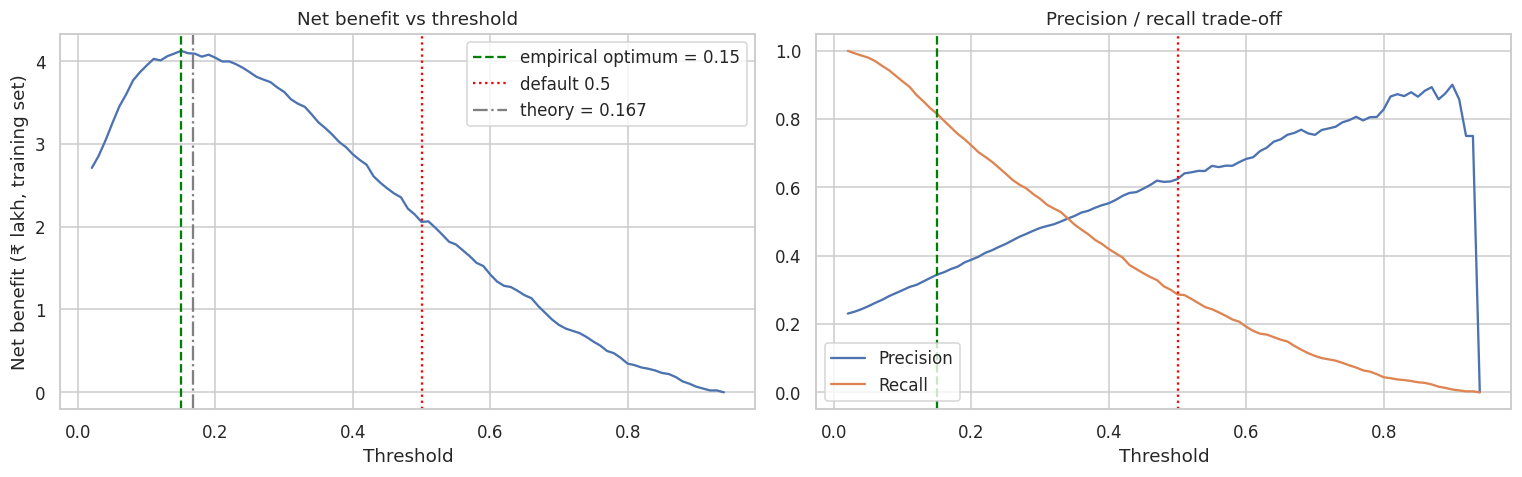

Chosen threshold: 0.15


In [9]:
best_model = models[best_name]
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def net_benefit(y_true, p, thr):
    flag = p >= thr
    tp = ((flag) & (y_true == 1)).sum(); fp = ((flag) & (y_true == 0)).sum()
    return tp * (SAVE_RATE * LTV - COUPON) - fp * COUPON

thresholds = np.arange(0.02, 0.95, 0.01)
nb = np.array([net_benefit(y_train.values, oof, t) for t in thresholds])
best_thr = thresholds[nb.argmax()]
theory_thr = COUPON / (SAVE_RATE * LTV)

prec = [((oof >= t) & (y_train.values == 1)).sum() / max((oof >= t).sum(), 1) for t in thresholds]
rec  = [((oof >= t) & (y_train.values == 1)).sum() / y_train.sum() for t in thresholds]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(thresholds, nb / 1e5); ax[0].axvline(best_thr, color="green", ls="--", label=f"empirical optimum = {best_thr:.2f}")
ax[0].axvline(0.5, color="red", ls=":", label="default 0.5"); ax[0].axvline(theory_thr, color="grey", ls="-.", label=f"theory = {theory_thr:.3f}")
ax[0].set_xlabel("Threshold"); ax[0].set_ylabel("Net benefit (₹ lakh, training set)"); ax[0].set_title("Net benefit vs threshold"); ax[0].legend()
ax[1].plot(thresholds, prec, label="Precision"); ax[1].plot(thresholds, rec, label="Recall")
ax[1].axvline(best_thr, color="green", ls="--"); ax[1].axvline(0.5, color="red", ls=":")
ax[1].set_xlabel("Threshold"); ax[1].set_title("Precision / recall trade-off"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Chosen threshold: {best_thr:.2f}")

## 9. Final evaluation on the untouched test set

Test ROC-AUC: 0.774 | Test PR-AUC: 0.540 (chance = 0.228)

=== Default 0.5 threshold ===
              precision    recall  f1-score   support

           0       0.81      0.95      0.88       927
           1       0.61      0.25      0.36       273

    accuracy                           0.79      1200
   macro avg       0.71      0.60      0.62      1200
weighted avg       0.77      0.79      0.76      1200

=== Cost-optimal threshold (0.15) ===
              precision    recall  f1-score   support

           0       0.92      0.51      0.66       927
           1       0.34      0.84      0.48       273

    accuracy                           0.59      1200
   macro avg       0.63      0.68      0.57      1200
weighted avg       0.79      0.59      0.62      1200



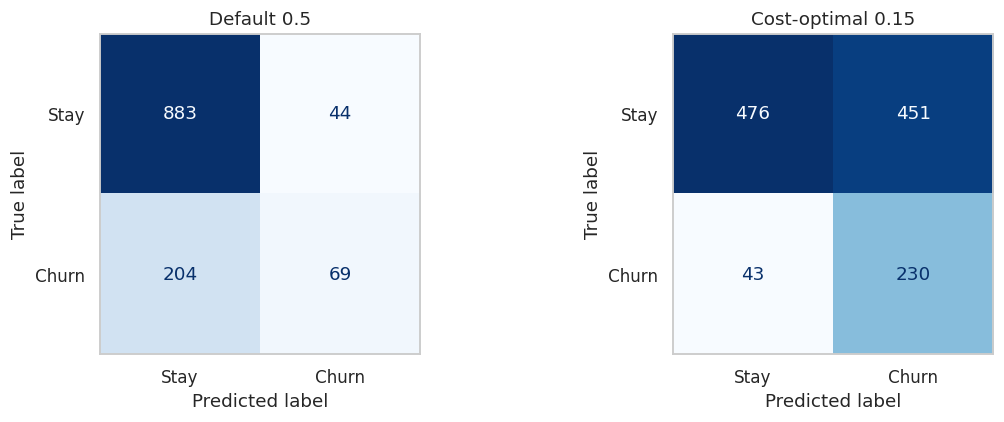

In [10]:
final_model = models[best_name].fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC: {roc_auc_score(y_test, p_test):.3f} | Test PR-AUC: {average_precision_score(y_test, p_test):.3f} (chance = {y_test.mean():.3f})\n")

pred_default = (p_test >= 0.5).astype(int)
pred_opt = (p_test >= best_thr).astype(int)

print("=== Default 0.5 threshold ==="); print(classification_report(y_test, pred_default, digits=2))
print(f"=== Cost-optimal threshold ({best_thr:.2f}) ==="); print(classification_report(y_test, pred_opt, digits=2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, pred, t in zip(ax, [pred_default, pred_opt], ["Default 0.5", f"Cost-optimal {best_thr:.2f}"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(t); a.grid(False)
plt.tight_layout(); plt.show()

In [11]:
def strategy_row(name, flag):
    flag = np.asarray(flag).astype(bool); yt = y_test.values
    tp = (flag & (yt == 1)).sum(); fp = (flag & (yt == 0)).sum()
    nb_ = tp * (SAVE_RATE * LTV - COUPON) - fp * COUPON
    return {"strategy": name, "customers_targeted": int(flag.sum()), "churners_reached": int(tp),
            "recall": tp / yt.sum(), "precision": tp / max(flag.sum(), 1),
            "coupon_spend_₹": int(flag.sum() * COUPON), "net_benefit_₹": int(nb_),
            "net_benefit_per_10k_customers_₹": int(nb_ / len(yt) * 10000)}

strategies = pd.DataFrame([
    strategy_row("Do nothing", np.zeros(len(y_test))),
    strategy_row("Offer everyone", np.ones(len(y_test))),
    strategy_row("Model @ default 0.5", p_test >= 0.5),
    strategy_row(f"Model @ cost-optimal {best_thr:.2f}", p_test >= best_thr),
])
(strategies.style.format({"recall": "{:.0%}", "precision": "{:.0%}", "coupon_spend_₹": "₹{:,}",
                          "net_benefit_₹": "₹{:,}", "net_benefit_per_10k_customers_₹": "₹{:,}"}))

,strategy,customers_targeted,churners_reached,recall,precision,coupon_spend_₹,net_benefit_₹,net_benefit_per_10k_customers_₹
0,Do nothing,0,0,0%,0%,₹0,₹0,₹0
1,Offer everyone,1200,273,100%,23%,"₹180,000","₹65,700","₹547,500"
2,Model @ default 0.5,113,69,25%,61%,"₹16,950","₹45,150","₹376,250"
3,Model @ cost-optimal 0.15,681,230,84%,34%,"₹102,150","₹104,850","₹873,750"


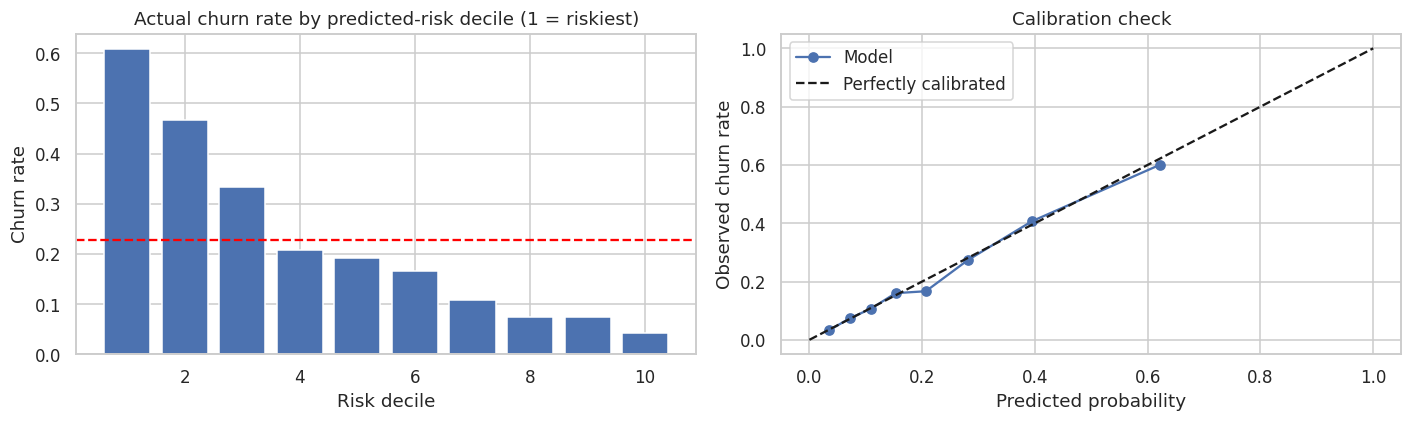

,customers,churners,churn_rate,avg_risk,cum_% of churners captured,lift
decile,,,,,,
1,120,73,61%,66%,27%,2.67x
2,120,56,47%,43%,47%,2.05x
3,120,40,33%,34%,62%,1.47x
4,120,25,21%,25%,71%,0.92x
5,120,23,19%,20%,80%,0.84x
6,120,20,17%,16%,87%,0.73x
7,120,13,11%,12%,92%,0.48x
8,120,9,8%,9%,95%,0.33x
9,120,9,8%,6%,98%,0.33x


In [12]:
# Lift / gain: how concentrated are churners among the highest-risk customers?
d = pd.DataFrame({"y": y_test.values, "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
d["decile"] = pd.qcut(d.index, 10, labels=range(1, 11))
gain = d.groupby("decile", observed=True).agg(customers=("y", "size"), churners=("y", "sum"), churn_rate=("y", "mean"), avg_risk=("p", "mean"))
gain["cum_% of churners captured"] = gain.churners.cumsum() / gain.churners.sum()
gain["lift"] = gain.churn_rate / y_test.mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(gain.index.astype(int), gain.churn_rate, color="#4C72B0"); ax[0].axhline(y_test.mean(), color="red", ls="--")
ax[0].set_title("Actual churn rate by predicted-risk decile (1 = riskiest)"); ax[0].set_xlabel("Risk decile"); ax[0].set_ylabel("Churn rate")
pt, pp = calibration_curve(y_test, p_test, n_bins=8, strategy="quantile")
ax[1].plot(pp, pt, marker="o", label="Model"); ax[1].plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Observed churn rate"); ax[1].set_title("Calibration check"); ax[1].legend()
plt.tight_layout(); plt.show()
gain.round(3).style.format({"churn_rate": "{:.0%}", "avg_risk": "{:.0%}", "cum_% of churners captured": "{:.0%}", "lift": "{:.2f}x"})

## 10. Explainability: *why* do customers churn?

Three complementary views. Agreement between them gives confidence.

1. **Logistic-regression coefficients** (on standardised features, directional, easy to explain)
2. **Permutation importance** on the test set (model-agnostic: how much PR-AUC drops when a feature is shuffled)
3. **SHAP** (per-customer contribution and direction)

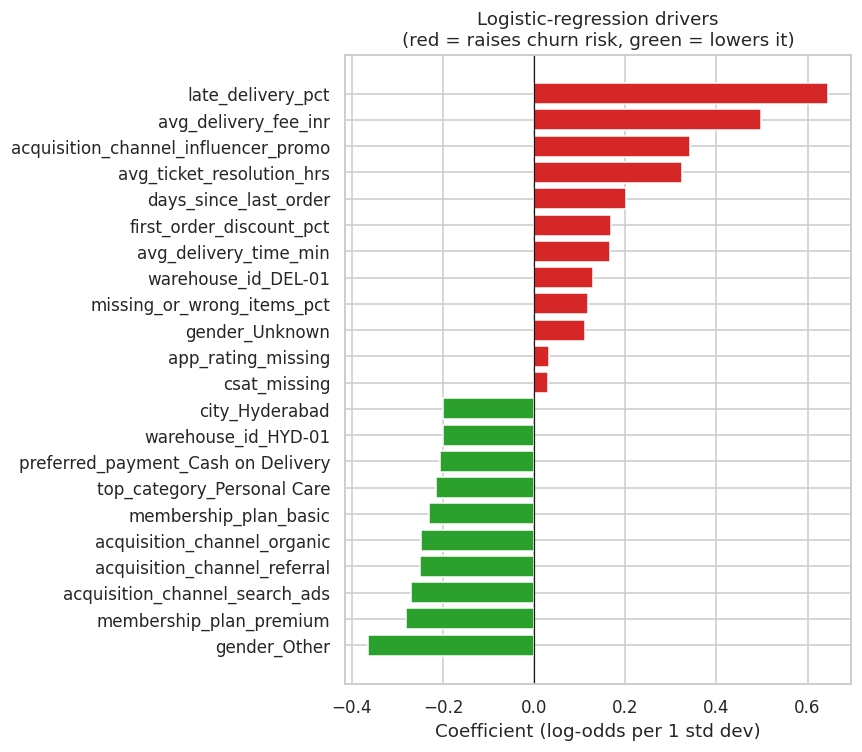

In [13]:
# 1) Directional coefficients from the logistic regression
lr_pipe = models["Logistic Regression"].fit(X_train, y_train)
names = lr_pipe.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in names]).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(12)])
plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values, color=["#2ca02c" if v < 0 else "#d62728" for v in top.values])
plt.axvline(0, color="k", lw=0.8); plt.title("Logistic-regression drivers\n(red = raises churn risk, green = lowers it)")
plt.xlabel("Coefficient (log-odds per 1 std dev)"); plt.tight_layout(); plt.show()

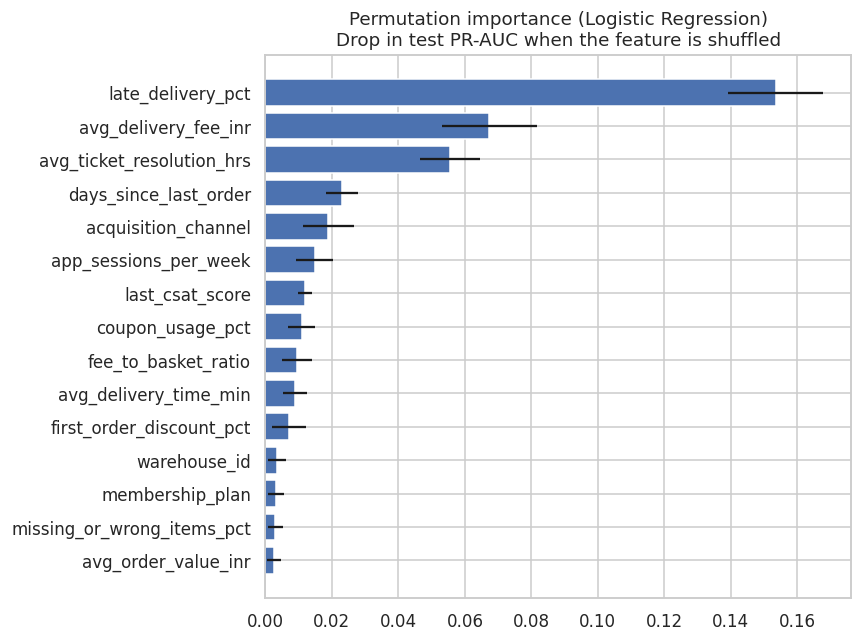

In [14]:
# 2) Permutation importance on the final model (computed on raw columns, test set)
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision", n_repeats=15, random_state=RANDOM_STATE, n_jobs=1)
pi_s = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
pi_err = pd.Series(pi.importances_std, index=X_test.columns)[pi_s.index]
top15 = pi_s.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top15.index, top15.values, xerr=pi_err[top15.index].values, color="#4C72B0")
plt.title(f"Permutation importance ({best_name})\nDrop in test PR-AUC when the feature is shuffled"); plt.tight_layout(); plt.show()

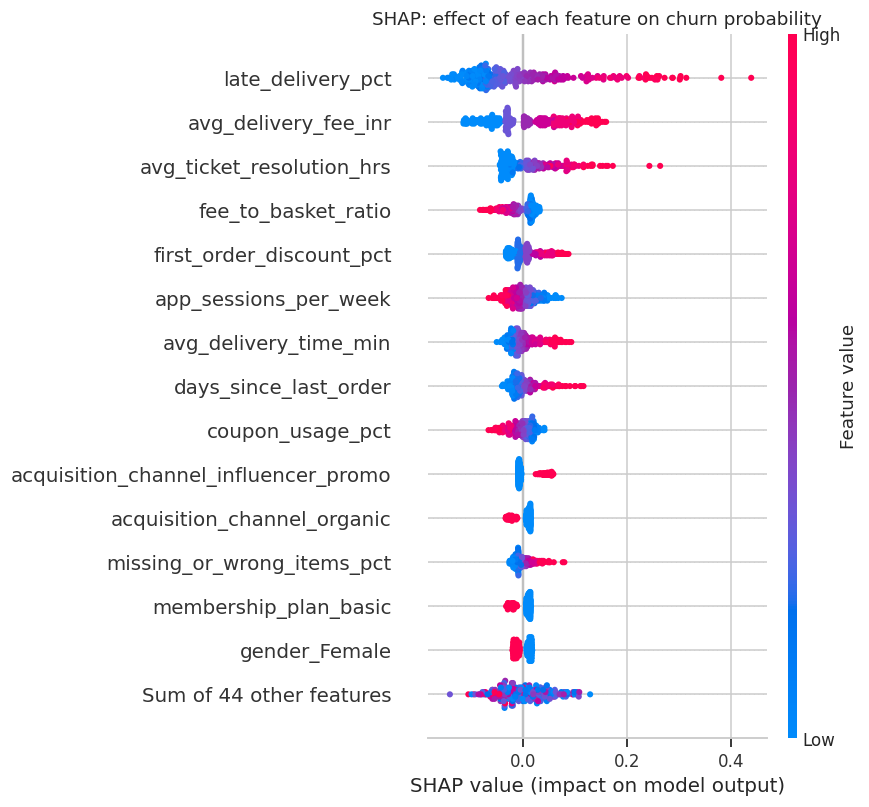

In [15]:
# 3) SHAP: direction and size of each feature's effect
try:
    import shap
    pre = final_model.named_steps["pre"]; clf = final_model.named_steps["clf"]
    feat_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
    Xt_test = pd.DataFrame(pre.transform(X_test), columns=feat_names)
    Xt_bg = pd.DataFrame(pre.transform(X_train.sample(150, random_state=RANDOM_STATE)), columns=feat_names)
    sample = Xt_test.sample(min(300, len(Xt_test)), random_state=RANDOM_STATE)
    masker = shap.maskers.Independent(Xt_bg, max_samples=150)
    explainer = shap.Explainer(lambda Z: clf.predict_proba(pd.DataFrame(Z, columns=feat_names))[:, 1], masker)
    sv = explainer(sample, silent=True)
    shap.plots.beeswarm(sv, max_display=15, show=False); plt.title("SHAP: effect of each feature on churn probability")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("SHAP step skipped:", e)

## 11. Effect sizes: what does fixing each cause buy us?

A simple, model-based what-if: take the high-risk customers, improve **one lever at a time** to a healthy level, and see how much the average predicted churn probability falls. This is a sensitivity estimate (correlational, not causal), but it helps prioritise.

In [16]:
def what_if(changes, label, mask=None):
    Xw = X_test.copy()
    m = mask if mask is not None else pd.Series(True, index=Xw.index)
    for col, fn in changes.items():
        Xw.loc[m, col] = fn(Xw.loc[m, col])
    before = final_model.predict_proba(X_test.loc[m])[:, 1].sum()
    after  = final_model.predict_proba(Xw.loc[m])[:, 1].sum()
    return {"scenario": label, "customers_affected": int(m.sum()), "churners_avoided (expected)": before - after,
            "% reduction in expected churners": (before - after) / before}

bad_wh = X_test.warehouse_id == "DEL-02"
healthy_delivery = X_test[~bad_wh].avg_delivery_time_min.median()
healthy_late = X_test[~bad_wh].late_delivery_pct.median()
scenarios = [
    what_if({"avg_delivery_time_min": lambda s: np.minimum(s, healthy_delivery),
             "late_delivery_pct": lambda s: np.minimum(s, healthy_late)}, "Bring DEL-02 delivery to network-median level", mask=bad_wh),
    what_if({"avg_delivery_time_min": lambda s: np.minimum(s, 35), "late_delivery_pct": lambda s: np.minimum(s, 25)},
            "Cap delivery time at 35 min and lateness at 25% (all customers)"),
    what_if({"avg_ticket_resolution_hrs": lambda s: np.minimum(s, 12)}, "Cap ticket resolution at 12h (all customers)"),
    what_if({"avg_delivery_fee_inr": lambda s: np.minimum(s, 29), "fee_to_basket_ratio": lambda s: np.minimum(s, 0.08)},
            "Cap delivery fee at ₹29 (all customers)"),
    what_if({"first_order_discount_pct": lambda s: np.minimum(s, 30)}, "Cap first-order discount at 30%"),
    what_if({"missing_or_wrong_items_pct": lambda s: np.minimum(s, 5)}, "Cut wrong/missing items to <= 5%"),
]
wi = pd.DataFrame(scenarios).sort_values("churners_avoided (expected)", ascending=False)
wi.style.format({"churners_avoided (expected)": "{:.1f}", "% reduction in expected churners": "{:.1%}"})

,scenario,customers_affected,churners_avoided (expected),% reduction in expected churners
0,Bring DEL-02 delivery to network-median level,125,37.6,60.1%
1,Cap delivery time at 35 min and lateness at 25% (all customers),1200,35.7,12.7%
3,Cap delivery fee at ₹29 (all customers),1200,23.5,8.4%
2,Cap ticket resolution at 12h (all customers),1200,21.5,7.7%
4,Cap first-order discount at 30%,1200,4.8,1.7%
5,Cut wrong/missing items to <= 5%,1200,4.2,1.5%


## 12. Retention playbook: risk tiers for every customer

We score **every** customer with honest out-of-fold predictions (the model never scored a customer it was trained on), then split them into tiers using the cost-based threshold.

In [17]:
oof_all = cross_val_predict(models[best_name], X, y, cv=cv, method="predict_proba")[:, 1]
scored = df[["customer_id", "city", "warehouse_id", "acquisition_channel", "membership_plan", TARGET]].copy()
scored["churn_risk"] = oof_all
scored["risk_tier"] = pd.cut(scored.churn_risk, [-0.01, best_thr, 0.50, 1.0], labels=["Low", "Medium", "High"])

tiers = (scored.groupby("risk_tier", observed=True)
         .agg(customers=("customer_id", "size"), avg_risk=("churn_risk", "mean"), actual_churn_rate=(TARGET, "mean"), churners=(TARGET, "sum"))
         .reindex(["High", "Medium", "Low"]))
tiers["% of customers"] = tiers.customers / tiers.customers.sum()
tiers["% of all churners"] = tiers.churners / tiers.churners.sum()
tiers["offer_cost_if_targeted_₹"] = tiers.customers * COUPON
tiers["expected_net_benefit_₹"] = tiers.churners * (SAVE_RATE * LTV - COUPON) - (tiers.customers - tiers.churners) * COUPON
display(tiers.style.format({"avg_risk": "{:.0%}", "actual_churn_rate": "{:.0%}", "% of customers": "{:.0%}", "% of all churners": "{:.0%}",
                            "offer_cost_if_targeted_₹": "₹{:,.0f}", "expected_net_benefit_₹": "₹{:,.0f}"}))

scored.sort_values("churn_risk", ascending=False).to_csv("churn_risk_scores.csv", index=False)
print("Saved churn_risk_scores.csv (every customer, out-of-fold risk and tier)")

,customers,avg_risk,actual_churn_rate,churners,% of customers,% of all churners,offer_cost_if_targeted_₹,expected_net_benefit_₹
risk_tier,,,,,,,,
High,632,65%,62%,391,11%,29%,"₹94,800","₹257,100"
Medium,2633,28%,28%,727,44%,53%,"₹394,950","₹259,350"
Low,2735,8%,9%,245,46%,18%,"₹410,250","₹-189,750"


Saved churn_risk_scores.csv (every customer, out-of-fold risk and tier)


## 13. Headline numbers

In [18]:
opt = strategies.iloc[3]; dflt = strategies.iloc[2]; allc = strategies.iloc[1]
print(f"Best model: {best_name}  |  CV PR-AUC {cv_table.loc[best_name,'PR-AUC']:.2f}  |  Test PR-AUC {average_precision_score(y_test, p_test):.2f} (chance {y_test.mean():.2f})")
print(f"Recall on churners:  default 0.5 threshold = {dflt.recall:.0%}   ->   cost-optimal {best_thr:.2f} threshold = {opt.recall:.0%}")
print(f"Precision at cost-optimal threshold: {opt.precision:.0%}")
print(f"Net benefit per 10,000 customers: model = ₹{opt['net_benefit_per_10k_customers_₹']:,} | offer-everyone = ₹{allc['net_benefit_per_10k_customers_₹']:,} | default-0.5 model = ₹{dflt['net_benefit_per_10k_customers_₹']:,}")
print("\nTop churn evidence (relative risk):")
print(evidence[["hypothesis", "relative_risk", "% of all churners"]].head(5).to_string(index=False, formatters={"relative_risk": "{:.2f}x".format, "% of all churners": "{:.0%}".format}))

Best model: Logistic Regression  |  CV PR-AUC 0.53  |  Test PR-AUC 0.54 (chance 0.23)
Recall on churners:  default 0.5 threshold = 25%   ->   cost-optimal 0.15 threshold = 84%
Precision at cost-optimal threshold: 34%
Net benefit per 10,000 customers: model = ₹873,750 | offer-everyone = ₹547,500 | default-0.5 model = ₹376,250

Top churn evidence (relative risk):
                           hypothesis relative_risk % of all churners
Ops: late deliveries >= 40% of orders         3.31x               14%
     Ops: avg delivery time >= 40 min         2.68x               36%
                Ops: warehouse DEL-02         2.48x               24%
    Support: ticket resolution >= 24h         1.79x               19%
         Finance: delivery fee >= ₹39         1.69x               54%


## 14. Findings and recommendations

**Answer to "who is right?": mostly Operations, with Marketing and Finance partly right, and Support contributing.**

| # | Finding (evidence from this notebook) | Recommendation | Owner | Expected impact |
|---|---|---|---|---|
| 1 | **Warehouse DEL-02 is the single biggest hotspot.** Churn is ~48% vs ~20% elsewhere (2.5x), with ~45 min average delivery and ~36% late orders. It holds ~11% of customers but ~24% of churners. The what-if shows bringing it to network-median delivery removes the largest block of expected churn. | Treat as an operations emergency: audit riders, picking and slotting, and stock availability at DEL-02. Add capacity or re-route orders to DEL-01 until delivery time is back near 31 min. | Head of Operations (Delhi) | Largest single lever in the what-if table |
| 2 | **Slow and late delivery is a network-wide driver, not only a DEL-02 issue.** Customers with 40+ min average delivery churn at ~47% (2.7x) and make up ~36% of all churners. Hyderabad (HYD-01) shows a milder version (~26%). | Set a service-level target (for example, under 35 min average and under 25% late) per warehouse, publish a weekly dashboard, and review HYD-01 next. | Operations | Second-largest lever in the what-if table |
| 3 | **Slow ticket resolution hurts.** Customers whose tickets take 24h+ to resolve churn at ~37% (1.8x). This is concentrated in Delhi warehouses (~25h average vs ~15h elsewhere). | Add an SLA of 12h for resolution, prioritise tickets from customers with a late order, and add Delhi support capacity. Support is not overwhelmed everywhere, so this is a targeted fix. | Head of Support | ~8% fewer expected churners in the what-if |
| 4 | **Marketing is right about acquisition quality.** Customers who joined on a 40%+ first-order discount churn at ~34% and influencer_promo customers at ~31%, vs ~21% outside those segments. | Cap first-order discounts at ~30%, shift budget from deep-discount influencer campaigns to referral, search and organic, and judge channels by 60-day retention, not by sign-ups. | Marketing | Smaller per-customer effect, but it also improves ROI on the 35% budget increase |
| 5 | **Finance is partly right about fees.** Customers paying ₹39+ delivery fees churn at ~30% (1.7x) and make up ~54% of churners, but fees are tangled up with basket size and membership, so treat this as a signal to test rather than proof. | A/B test a lower fee or a free-delivery threshold for small baskets (do not cut fees blindly). | Finance + Product | ~8% fewer expected churners in the what-if (to be validated) |
| 6 | **Membership protects.** Premium members churn at under ~10% vs ~27% for non-members. | Push free-trial and low-price membership offers to engaged non-members, especially those with a recent late delivery. | Growth / Product | Retention plus higher order frequency |
| 7 | **Wrong or missing items are not a main driver here.** Relative risk is only ~1.1x (MUM-02 has a high wrong-item rate but normal churn). | Keep monitoring, but do not prioritise this over delivery and support. | Operations | Low |

**Retention strategy for the model's high-risk customers (see section 12):**

* **High tier (risk 50%+):** personal outreach plus a ₹150 offer and an apology if they had a late delivery or slow ticket. Highest expected return.
* **Medium tier (between the cost-optimal threshold of ~15% and 50%):** automated in-app or WhatsApp offer (coupon, free-delivery day, membership trial). Positive expected value at the 30% save-rate assumption.
* **Low tier (below ~15%):** no offer. Offering coupons here loses money.
* **Run it as an A/B test**: hold out 10% of the flagged customers, measure the true save rate, then re-tune the threshold with the real number.

**Model summary:** the model targets about 84% of churners at a cost-optimal threshold of ~0.15, compared with ~25% at the default 0.5, and delivers roughly 60% more net benefit than offering everyone a coupon (the exact figures are printed in section 13).

## 15. Limitations and next steps

* **Synthetic/observational data:** the drivers are associations. The only way to confirm that "fixing X reduces churn" is an A/B test, which should be done before large rollouts.
* **Save-rate assumption (30%)** drives the threshold. Run a small coupon experiment to measure the true value. If the save rate is 15%, the break-even threshold doubles (~33%).
* **Single snapshot:** a time-based split (train on earlier cohorts, test on later) would be a stricter test and should be used once more history is available.
* **Imbalance and calibration** were handled via threshold and probability checks; re-check calibration after every retrain.
* **Monitoring:** track PR-AUC, calibration and segment churn monthly; retrain when they drift.
* **Fairness/privacy:** `age` and `gender` should be reviewed (and probably excluded) before using the score to decide who receives offers.